# 07 · Feature engineering for the bad-review model

In `04_ML_bad_reviews`, three tree-based models reached the same ceiling (~0.70 ROC-AUC, ~0.33 PR-AUC). That points to the **features**, not the algorithm, as the limit. This notebook adds 12 new features in five groups and measures what each group adds.

| Group | Features | Hypothesis |
|---|---|---|
| Seller history | `seller_past_bad_rate`, `seller_past_late_rate`, `seller_past_reviews`, `seller_tenure_days` | Sellers with a bad track record keep generating bad reviews |
| Seller shipped late | `seller_shipped_late` | Separates a slow seller from a slow carrier |
| Regional logistics | `state_late_rate_30d` | Captures logistics crises (like early 2018) that the model could not see before |
| Purchase calendar | `purchase_month`, `purchase_dow`, `purchase_hour` | Seasonality and peak periods (Black Friday, holidays) |
| Product attributes | `photos_qty`, `description_length`, `weight_g`, `volume_cm3` | Poor listings create wrong expectations; bulky items get damaged |

**No leakage:** the model predicts at delivery time, so every feature uses only information that existed **before this order was delivered**. A seller's bad-review rate counts only reviews answered before that moment.

**Method:** same temporal split, same model (HistGradientBoosting) and same preprocessing as notebook 04. Only the feature set changes, so any difference in PR-AUC comes from the features.

Requires `04_ML_bad_reviews` to have run first (it builds `gold.ml_features_bad_review`, the base feature table).

In [0]:
%pip install scikit-learn mlflow --quiet

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
dbutils.library.restartPython()

## 1. Build the new feature table

`gold.ml_features_bad_review_v2` = the 04 feature table + 12 new columns. How each one is built:

- **Seller history:** every earlier order of the same seller is joined, keeping only reviews answered and deliveries completed **before** this order's delivery. Rates are **smoothed** toward the training-period average with 10 pseudo-orders, so a seller with 1 review is not scored as 0% or 100%.
- **Seller shipped late:** the carrier pickup date (`order_delivered_carrier_date`) is compared with the seller's shipping deadline (`shipping_limit_ts`). The pickup date is not in silver yet, so it is read from bronze.
- **Regional logistics:** share of late deliveries in the customer's state over the **previous 30 days** (window that excludes the delivery day), smoothed with 20 pseudo-orders for small states.
- **Calendar and product:** taken from the purchase timestamp and from the order's main product (the most expensive item).

In [0]:
%sql
CREATE OR REPLACE TABLE workspace.gold.ml_features_bad_review_v2 AS
WITH
-- Carrier pickup date: only in bronze for now
carrier AS (
  SELECT order_id, to_timestamp(order_delivered_carrier_date) AS carrier_ts
  FROM (SELECT *, row_number() OVER (PARTITION BY order_id ORDER BY _ingest_ts DESC) AS rn
        FROM workspace.bronze.orders)
  WHERE rn = 1
),
-- Order timeline with the late flag (same definition as fact_orders)
timeline AS (
  SELECT o.order_id, o.customer_id, o.purchase_ts, o.delivered_ts,
         o.delivery_delay_days > 0 AS is_late,
         c.carrier_ts
  FROM workspace.silver.orders o
  LEFT JOIN carrier c ON o.order_id = c.order_id
),
-- Main item of each order (most expensive): its seller and product
item_main AS (
  SELECT order_id,
         max_by(seller_id, price)  AS seller_id,
         max_by(product_id, price) AS product_id
  FROM workspace.silver.order_items
  GROUP BY order_id
),
-- Every (seller, order) pair with the order's delivery outcome and review
seller_orders AS (
  SELECT DISTINCT i.seller_id, i.order_id, t.delivered_ts, t.is_late,
         r.answered_ts, r.review_score <= 2 AS is_bad
  FROM workspace.silver.order_items i
  JOIN timeline t ON i.order_id = t.order_id
  LEFT JOIN workspace.silver.order_reviews r ON i.order_id = r.order_id
),
-- Prediction rows: the orders of the 04 feature table, with their delivery moment
base AS (
  SELECT f.order_id, f.customer_state, m.seller_id, m.product_id, t.purchase_ts, t.delivered_ts
  FROM workspace.gold.ml_features_bad_review f
  JOIN item_main m ON f.order_id = m.order_id
  JOIN timeline t  ON f.order_id = t.order_id
),
-- Smoothing priors, computed on the training period only (before 2018-05-01)
priors AS (
  SELECT (SELECT avg(CAST(review_score <= 2 AS DOUBLE)) FROM workspace.silver.order_reviews
          WHERE answered_ts < '2018-05-01') AS prior_bad,
         (SELECT avg(CAST(is_late AS DOUBLE)) FROM timeline
          WHERE delivered_ts < '2018-05-01') AS prior_late
),
-- Seller history: only what was known before THIS order was delivered
seller_hist AS (
  SELECT b.order_id,
         count_if(so.answered_ts < b.delivered_ts AND so.is_bad IS NOT NULL) AS seller_past_reviews,
         count_if(so.answered_ts < b.delivered_ts AND so.is_bad)             AS seller_past_bad,
         count_if(so.delivered_ts < b.delivered_ts AND so.is_late IS NOT NULL) AS seller_past_deliveries,
         count_if(so.delivered_ts < b.delivered_ts AND so.is_late)           AS seller_past_late
  FROM base b
  LEFT JOIN seller_orders so
         ON so.seller_id = b.seller_id
        AND so.order_id <> b.order_id
        AND (so.answered_ts < b.delivered_ts OR so.delivered_ts < b.delivered_ts)
  GROUP BY b.order_id
),
seller_first AS (
  SELECT i.seller_id, min(t.purchase_ts) AS first_sale_ts
  FROM workspace.silver.order_items i
  JOIN timeline t ON i.order_id = t.order_id
  GROUP BY i.seller_id
),
-- Did the seller hand the order to the carrier after its shipping deadline?
shipped AS (
  SELECT i.order_id, max(CAST(t.carrier_ts > i.shipping_limit_ts AS INT)) AS seller_shipped_late
  FROM workspace.silver.order_items i
  JOIN timeline t ON i.order_id = t.order_id
  GROUP BY i.order_id
),
-- Late deliveries per customer state and day, then a 30-day window that excludes the current day
state_daily AS (
  SELECT cu.state, CAST(t.delivered_ts AS DATE) AS day,
         count(*) AS delivered_n, count_if(t.is_late) AS late_n
  FROM timeline t
  JOIN workspace.silver.customers cu ON t.customer_id = cu.customer_id
  WHERE t.delivered_ts IS NOT NULL
  GROUP BY cu.state, CAST(t.delivered_ts AS DATE)
),
state_30d AS (
  SELECT state, day,
         sum(late_n)      OVER (PARTITION BY state ORDER BY unix_date(day)
                                RANGE BETWEEN 30 PRECEDING AND 1 PRECEDING) AS late_30d,
         sum(delivered_n) OVER (PARTITION BY state ORDER BY unix_date(day)
                                RANGE BETWEEN 30 PRECEDING AND 1 PRECEDING) AS delivered_30d
  FROM state_daily
)
SELECT f.*,
       -- Seller history (smoothed rates)
       (sh.seller_past_bad  + 10 * p.prior_bad)  / (sh.seller_past_reviews    + 10) AS seller_past_bad_rate,
       (sh.seller_past_late + 10 * p.prior_late) / (sh.seller_past_deliveries + 10) AS seller_past_late_rate,
       sh.seller_past_reviews,
       datediff(b.purchase_ts, sf.first_sale_ts)                                    AS seller_tenure_days,
       -- Seller shipped late
       sp.seller_shipped_late,
       -- Regional logistics (smoothed)
       (coalesce(s30.late_30d, 0) + 20 * p.prior_late)
         / (coalesce(s30.delivered_30d, 0) + 20)                                    AS state_late_rate_30d,
       -- Purchase calendar
       month(b.purchase_ts)      AS purchase_month,
       dayofweek(b.purchase_ts)  AS purchase_dow,
       hour(b.purchase_ts)       AS purchase_hour,
       -- Product attributes (main product)
       pr.photos_qty, pr.description_length, pr.weight_g, pr.volume_cm3
FROM workspace.gold.ml_features_bad_review f
JOIN base b                ON f.order_id = b.order_id
CROSS JOIN priors p
LEFT JOIN seller_hist sh   ON f.order_id = sh.order_id
LEFT JOIN seller_first sf  ON b.seller_id = sf.seller_id
LEFT JOIN shipped sp       ON f.order_id = sp.order_id
LEFT JOIN state_30d s30    ON s30.state = f.customer_state AND s30.day = CAST(b.delivered_ts AS DATE)
LEFT JOIN workspace.gold.dim_product pr ON b.product_id = pr.product_id;

num_affected_rows,num_inserted_rows


## 2. Sanity checks
Before modeling, check that the new table has one row per order, how many nulls each new feature has, and that the leakage guard works: a seller's **first** delivered order must have zero past reviews.

In [0]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

BLUE, GRAY, INK, INK_2 = "#2a78d6", "#a3a29d", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#ebeae6", "axes.axisbelow": True, "font.size": 10,
                     "axes.titlelocation": "left", "axes.titleweight": "bold"})

NEW_GROUPS = {
    "seller history":      ["seller_past_bad_rate", "seller_past_late_rate", "seller_past_reviews", "seller_tenure_days"],
    "seller shipped late": ["seller_shipped_late"],
    "regional logistics":  ["state_late_rate_30d"],
    "purchase calendar":   ["purchase_month", "purchase_dow", "purchase_hour"],
    "product attributes":  ["photos_qty", "description_length", "weight_g", "volume_cm3"],
}
NEW_COLS = [c for cols in NEW_GROUPS.values() for c in cols]

BASE_NUM = ["order_value", "freight_value", "freight_ratio", "items_qty", "sellers_qty",
            "max_installments", "promised_days", "delivery_days", "delivery_delay_days",
            "same_state", "distance_km"]
CAT_COLS = ["main_payment_type", "main_category", "customer_state", "seller_state"]

df = spark.table("workspace.gold.ml_features_bad_review_v2").toPandas()
df["date_key"] = pd.to_datetime(df["date_key"])
df[BASE_NUM + NEW_COLS] = df[BASE_NUM + NEW_COLS].astype(float)   # DECIMAL -> float

base_rows = spark.table("workspace.gold.ml_features_bad_review").count()
print(f"Rows: {len(df):,} (base table: {base_rows:,}) · unique orders: {df['order_id'].nunique():,}")
assert len(df) == base_rows == df["order_id"].nunique(), "The new table must keep one row per order"

display(pd.DataFrame({"null_pct": df[NEW_COLS].isna().mean().round(4),
                      "mean": df[NEW_COLS].mean().round(3),
                      "min": df[NEW_COLS].min(), "max": df[NEW_COLS].max()}))

# Leakage guard: an order delivered before its seller's FIRST answered review cannot see any past review
checked, violations = spark.sql("""
    WITH main AS (
        SELECT order_id, max_by(seller_id, price) AS seller_id
        FROM workspace.silver.order_items GROUP BY order_id),
    first_review AS (
        SELECT i.seller_id, min(r.answered_ts) AS first_answer_ts
        FROM workspace.silver.order_items i
        JOIN workspace.silver.order_reviews r ON i.order_id = r.order_id
        GROUP BY i.seller_id)
    SELECT count(*), count_if(v.seller_past_reviews > 0)
    FROM workspace.gold.ml_features_bad_review_v2 v
    JOIN main m               ON v.order_id = m.order_id
    JOIN first_review fr      ON m.seller_id = fr.seller_id
    JOIN workspace.silver.orders o ON v.order_id = o.order_id
    WHERE o.delivered_ts <= fr.first_answer_ts
""").first()
print(f"Orders delivered before their seller's first review: {checked:,} · with past reviews (must be 0): {violations}")
assert violations == 0, "Leakage: an order sees seller reviews answered after its delivery"

Rows: 95,824 (base table: 95,824) · unique orders: 95,824


null_pct,mean,min,max
0.0,0.142,0.018888564660882623,0.663808551125505
0.0,0.055,0.003337310947540008,0.44200893070982644
0.0,183.06,0.0,1835.0
0.0,217.31,0.0,710.0
0.0,0.09,0.0,1.0
0.0,0.066,0.00211753355443328,0.4927420125162153
0.0,6.031,1.0,12.0
0.0,3.912,1.0,7.0
0.0,14.774,0.0,23.0
0.0141,2.252,1.0,20.0


Orders delivered before their seller's first review: 3,327 · with past reviews (must be 0): 0


## 3. Do the new features separate good from bad reviews?
A quick look before training: bad review rate by seller history (5 equal-size groups), by whether the seller shipped late, and by regional logistics pressure.

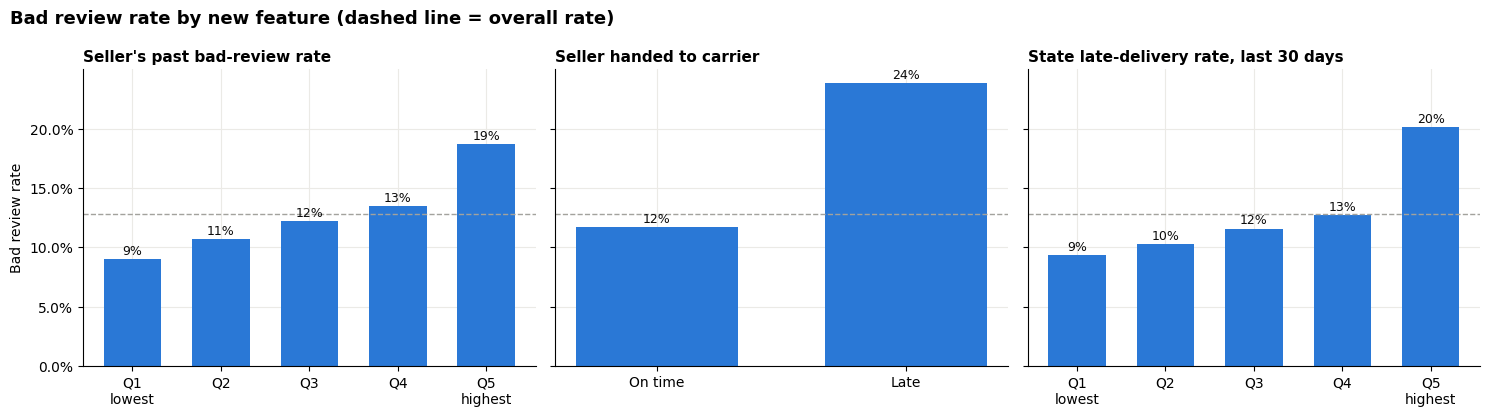

In [0]:
def rate_by_quintile(col):
    q = pd.qcut(df[col].rank(method="first"), 5, labels=["Q1\nlowest", "Q2", "Q3", "Q4", "Q5\nhighest"])
    return df.groupby(q, observed=True)["label"].mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
panels = [(rate_by_quintile("seller_past_bad_rate"), "Seller's past bad-review rate"),
          (df.groupby(df["seller_shipped_late"].map({0: "On time", 1: "Late"}))["label"].mean()
             .reindex(["On time", "Late"]), "Seller handed to carrier"),
          (rate_by_quintile("state_late_rate_30d"), "State late-delivery rate, last 30 days")]
for ax, (rates, title) in zip(axes, panels):
    ax.bar(range(len(rates)), rates.values, color=BLUE, width=0.65)
    ax.set_xticks(range(len(rates)), rates.index)
    for x, v in enumerate(rates.values):
        ax.text(x, v + 0.004, f"{v:.0%}", ha="center", fontsize=9, color=INK)
    ax.axhline(df["label"].mean(), color=GRAY, ls="--", lw=1)
    ax.set_title(title, fontsize=11)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].set_ylabel("Bad review rate")
fig.suptitle("Bad review rate by new feature (dashed line = overall rate)", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

## 4. Ablation: what does each feature group add?
Seven models, identical except for the features:
- **base:** the 04 features (reference).
- **base + one group:** isolates the contribution of each group.
- **all features:** base + the 12 new features.

Same temporal split (train before 2018-05-01, test after), same HistGradientBoosting settings as 04. Every run is logged to MLflow.

In [0]:
import mlflow
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, recall_score, precision_score

user = spark.sql("SELECT current_user()").first()[0]
mlflow.set_experiment(f"/Users/{user}/olist_bad_reviews")
mlflow.sklearn.autolog(disable=True)          # log metrics manually: faster than saving 7 models

cutoff = "2018-05-01"
train, test = df[df.date_key < cutoff], df[df.date_key >= cutoff]
y_train, y_test = train["label"], test["label"]
print(f"train: {len(train):,} | test: {len(test):,}")

def make_pipe(num_cols):
    """Same preprocessing and model as notebook 04; only the numeric feature list changes."""
    prep = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", min_frequency=50,
                                                sparse_output=False))]), CAT_COLS),
    ])
    model = HistGradientBoostingClassifier(class_weight="balanced", max_iter=300,
                                           learning_rate=0.05, random_state=42)
    return Pipeline([("prep", prep), ("model", model)])

def metrics(y, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {"test_roc_auc": roc_auc_score(y, proba), "test_pr_auc": average_precision_score(y, proba),
            "test_recall": recall_score(y, pred), "test_precision": precision_score(y, pred)}

experiments = {"base (04 features)": []}
experiments |= {f"+ {group}": cols for group, cols in NEW_GROUPS.items()}
experiments["all features"] = NEW_COLS

results, probas, pipes = {}, {}, {}
for name, extra in experiments.items():
    num_cols = BASE_NUM + extra
    with mlflow.start_run(run_name=f"fe · {name}"):
        pipe = make_pipe(num_cols).fit(train[num_cols + CAT_COLS], y_train)
        proba = pipe.predict_proba(test[num_cols + CAT_COLS])[:, 1]
        m = metrics(y_test, proba)
        mlflow.log_params({"feature_set": name, "n_features": len(num_cols + CAT_COLS)})
        mlflow.log_metrics(m)
    results[name], probas[name], pipes[name] = m, proba, pipe

res = pd.DataFrame(results).T
res["pr_auc_vs_base"] = res["test_pr_auc"] - res.loc["base (04 features)", "test_pr_auc"]
display(res.round(4).reset_index(names="feature_set"))

If you are using MLflow Tracing, you can migrate your traces to Unity Catalog for unlimited storage, fine-grained access controls, and queryability from notebooks, SQL, and dashboards. Learn more: https://docs.databricks.com/aws/en/mlflow3/genai/tracing/migrate-traces-to-uc


train: 70,582 | test: 25,242


feature_set,test_roc_auc,test_pr_auc,test_recall,test_precision,pr_auc_vs_base
base (04 features),0.6996,0.3255,0.4202,0.3136,0.0
+ seller history,0.7259,0.3404,0.4634,0.2958,0.0149
+ seller shipped late,0.7012,0.3256,0.4186,0.3106,1.0E-4
+ regional logistics,0.7051,0.3264,0.4115,0.3216,8.0E-4
+ purchase calendar,0.6981,0.3253,0.4131,0.3189,-2.0E-4
+ product attributes,0.7134,0.3288,0.4261,0.308,0.0033
all features,0.7282,0.3381,0.4566,0.3045,0.0126


### Selected model: base + seller history
The ablation shows that **seller history** is the only group with a clear gain, and it explains almost all of the improvement of the full model. The other groups add nothing because, at delivery time, the model already knows the actual delay: regional pressure, late dispatch and calendar effects are *causes* of delay whose effect is already captured. The simpler model (4 new features instead of 12) is kept.

**Is the gain real or noise?** A **bootstrap** resamples the test set 300 times and recomputes the PR-AUC gap against the base each time. If the 95% interval stays above 0, the improvement is robust.

In [0]:
SELECTED = "+ seller history"
BASE = "base (04 features)"

rng = np.random.default_rng(42)
yt = y_test.to_numpy()
for name in [SELECTED, "all features"]:
    diffs = []
    for _ in range(300):
        idx = rng.integers(0, len(yt), len(yt))
        diffs.append(average_precision_score(yt[idx], probas[name][idx])
                     - average_precision_score(yt[idx], probas[BASE][idx]))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    verdict = "robust improvement" if lo > 0 else "not significant (interval includes 0)"
    print(f"{name:>18} vs base: PR-AUC gain {np.mean(diffs):+.3f} · 95% interval [{lo:+.3f}, {hi:+.3f}] → {verdict}")

  + seller history vs base: PR-AUC gain +0.015 · 95% interval [+0.010, +0.019] → robust improvement
      all features vs base: PR-AUC gain +0.013 · 95% interval [+0.007, +0.018] → robust improvement


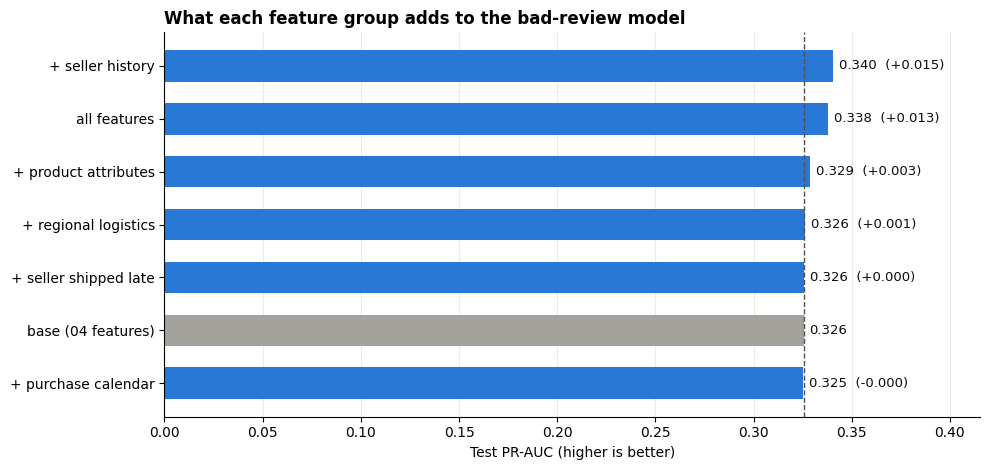

In [0]:
# Chart: PR-AUC per feature set, saved for the README
spark.sql("CREATE VOLUME IF NOT EXISTS workspace.gold.charts")

plot = res.sort_values("test_pr_auc")
base_val = res.loc["base (04 features)", "test_pr_auc"]
fig, ax = plt.subplots(figsize=(10, 4.8))
colors = [GRAY if n == "base (04 features)" else BLUE for n in plot.index]
ax.barh(plot.index, plot["test_pr_auc"], color=colors, height=0.6)
ax.axvline(base_val, color=INK_2, ls="--", lw=1)
for y, (v, d) in enumerate(zip(plot["test_pr_auc"], plot["pr_auc_vs_base"])):
    label = f"{v:.3f}" if abs(d) < 1e-9 else f"{v:.3f}  ({d:+.3f})"
    ax.text(v + 0.003, y, label, va="center", fontsize=9.5, color=INK)
ax.set_xlim(0, plot["test_pr_auc"].max() * 1.22)
ax.set_xlabel("Test PR-AUC (higher is better)")
ax.grid(axis="y", visible=False)
ax.set_title("What each feature group adds to the bad-review model")
plt.tight_layout()
fig.savefig("/Volumes/workspace/gold/charts/g7_feature_groups_pr_auc.png", dpi=160, bbox_inches="tight", facecolor="white")
plt.show()

## 5. Business impact: same alert budget, better alerts?
PR-AUC summarizes the whole curve. For the business, what matters is the decision threshold. For each model, the threshold is chosen on **validation** (most recent 20% of train, max F1), never on test, exactly as in notebook 04. Then precision and recall are compared on test.

In [0]:
from sklearn.metrics import precision_recall_curve

train_sorted = train.sort_values("date_key")
cut = int(len(train_sorted) * 0.8)
fit_part, val_part = train_sorted.iloc[:cut], train_sorted.iloc[cut:]

rows = []
for name in [BASE, SELECTED, "all features"]:
    num_cols = BASE_NUM + experiments[name]
    cols = num_cols + CAT_COLS
    val_proba = make_pipe(num_cols).fit(fit_part[cols], fit_part["label"]).predict_proba(val_part[cols])[:, 1]
    prec, rec, thr = precision_recall_curve(val_part["label"], val_proba)
    f1 = 2 * prec * rec / (prec + rec + 1e-9)
    t = float(thr[np.argmax(f1[:-1])])
    m = metrics(y_test, probas[name], threshold=t)
    rows.append({"model": name, "threshold": round(t, 2),
                 "test_recall": m["test_recall"], "test_precision": m["test_precision"],
                 "test_f1": 2 * m["test_recall"] * m["test_precision"] / (m["test_recall"] + m["test_precision"])})
display(pd.DataFrame(rows).round(3))

model,threshold,test_recall,test_precision,test_f1
base (04 features),0.68,0.293,0.468,0.36
+ seller history,0.68,0.312,0.452,0.369
all features,0.7,0.279,0.479,0.353


## 6. How does the selected model use the seller history?
Permutation importance of the selected model (base + seller history) on a test sample: how much PR-AUC drops when each feature is shuffled. New features are highlighted in blue.

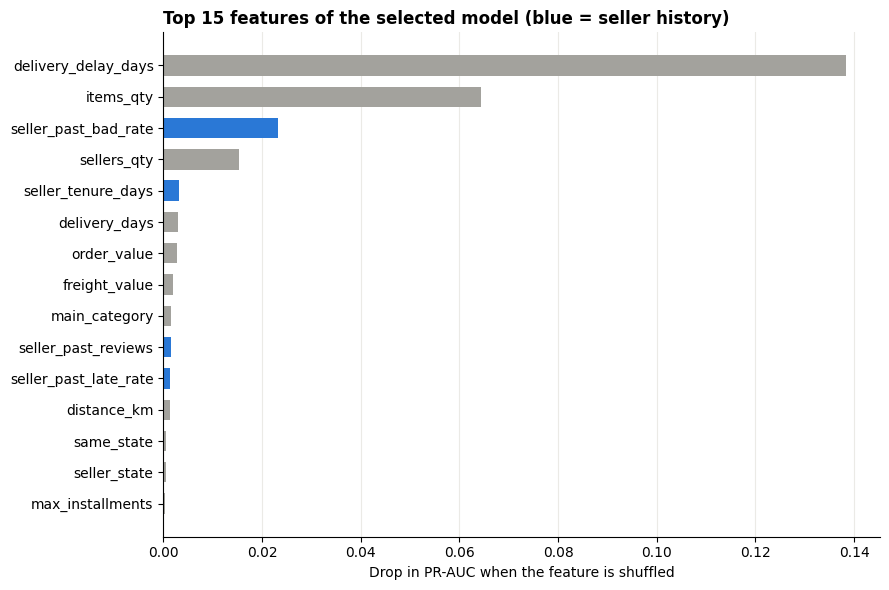

In [0]:
from sklearn.inspection import permutation_importance

sel_num = BASE_NUM + experiments[SELECTED]
sample = test.sample(n=min(8000, len(test)), random_state=42)
imp = permutation_importance(pipes[SELECTED], sample[sel_num + CAT_COLS], sample["label"],
                             scoring="average_precision", n_repeats=5, random_state=42)
imp_df = (pd.DataFrame({"feature": sel_num + CAT_COLS, "importance": imp.importances_mean})
            .sort_values("importance", ascending=False).head(15).iloc[::-1])

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(imp_df["feature"], imp_df["importance"],
        color=[BLUE if f in NEW_COLS else GRAY for f in imp_df["feature"]], height=0.65)
ax.set_xlabel("Drop in PR-AUC when the feature is shuffled")
ax.grid(axis="y", visible=False)
ax.set_title("Top 15 features of the selected model (blue = seller history)")
plt.tight_layout()
fig.savefig("/Volumes/workspace/gold/charts/g8_feature_importance_v2.png", dpi=160, bbox_inches="tight", facecolor="white")
plt.show()

## Conclusions

**What was tested:** 13 new leakage-safe features in 5 groups, each added to the 04 model one group at a time (ablation), with the same temporal split, model and preprocessing.

**Results (test set)**

| Model | ROC-AUC | PR-AUC | Recall* | Precision* | F1* |
|---|---|---|---|---|---|
| Base (04 features) | 0.700 | 0.326 | 29.3% | 46.8% | 0.360 |
| **+ Seller history (selected)** | **0.726** | **0.340** | **31.2%** | 45.2% | **0.369** |
| All 13 features | 0.728 | 0.338 | 27.9% | 47.9% | 0.353 |

*At the threshold chosen on validation for each model (0.68–0.70).

**Key findings**
- **Seller history is the only group with real signal:** +0.015 PR-AUC and +0.026 ROC-AUC. The bootstrap confirms it is not noise: the 95% interval [+0.010, +0.019] is entirely above zero. It explains all of the full model's gain with 4 features instead of 13, so the simpler model is selected.
- **Correlated is not the same as useful.** Late dispatch (24% vs 12% bad reviews) and regional congestion (20% vs 9% from lowest to highest quintile) are strongly related to bad reviews, but add nothing to the model. They are *causes* of delay, and the model already knows the actual delay (`delivery_delay_days`), so their information is redundant.
- **Seller history adds what delay cannot explain.** Sellers in the worst quintile of past bad reviews get 19% bad reviews vs 9% in the best one. `seller_past_bad_rate` becomes the 3rd most important feature, behind delivery delay and number of items, likely capturing product quality and service issues. `seller_past_late_rate` adds little, again because delay is already known.
- **Calendar and product attributes add no measurable value** (≤ +0.003 PR-AUC).
- **Business impact is moderate:** at the same threshold, the selected model detects more bad reviews (31.2% vs 29.3%) with similar precision. The main gain is a better risk ranking.